# Experiment 4: Spark Database and Descriptive Analytics

Name: ____________________    Class / Roll No: ____________________

## Aim

Create a Spark database (temporary SQL view) and perform descriptive and diagnostic analytics on a large dataset using PySpark: basic statistics, group-by queries, aggregations and Spark SQL programming.

## Theory

Apache Spark is a distributed cluster-computing framework. It keeps intermediate results in memory instead of writing them to disk after every stage like Hadoop MapReduce, which makes iterative and multi-stage analytics much faster.

- RDD (Resilient Distributed Dataset): an immutable collection of records split into partitions across worker nodes. Fault tolerance comes from the lineage graph. If a partition is lost, Spark replays only the operations that built that partition.
- Transformations vs actions: transformations (filter, map, reduceByKey) are lazy and only build a DAG plan. Actions (count, take, collect) trigger the actual execution.
- Narrow vs wide dependencies: filter and map work inside one partition. reduceByKey and groupBy need a shuffle, which moves records across the network so equal keys land together.
- Spark SQL and Catalyst: DataFrames can be registered as temporary views and queried with SQL. The Catalyst optimizer rewrites the plan (predicate pushdown, column pruning) before it becomes RDD stages.
- Window functions: LAG and NTILE compute over ordered groups of rows without collapsing the rows.

## Problem Statement

Build a distributed pipeline with PySpark RDDs and Spark SQL to study online food delivery in Indian cities: daily demand, payment behaviour and tipping, order size, delivery distance, rush hour slowdowns, surge fees, high value delivery corridors and pricing anomalies.

## Dataset

A synthetic dataset of about 2 million food delivery orders for January 2026, generated inside Spark and saved as Parquet (so the flow is the same as reading a real Parquet file). It is synthetic, so no download is needed and it will not break in Colab. The patterns in it (lunch and dinner peaks, weekend boost, surge fees reducing tipping, cash on delivery tips not recorded) are built in on purpose, so read the results as a demonstration of the technique and not as real market findings.

Columns:

- order_id, order_ts, delivered_ts: order and delivery timestamps
- rest_zone, cust_zone: restaurant and customer zone ids (1 to 40)
- distance_km, items_count, payment_code (1 UPI, 2 Card, 3 Cash on Delivery, 4 Wallet, 5 Net Banking)
- order_value, delivery_fee, surge_fee, discount, tip, total_amount (all in INR)

About 1 percent of rows are deliberately dirty (zero or missing distance or order value), and a few are pricing glitches, so that the cleaning step and the outlier query have something to find.

## Setup

Install PySpark, import the libraries, and start a local SparkSession. Shuffle partitions are set to 8 because the data is small for a cluster, and the default of 200 would create many tiny tasks. The session timezone is fixed so that HOUR() and DATE() behave the same everywhere.

In [ ]:
!pip install pyspark -q

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

spark = (SparkSession.builder
         .appName("Food_Delivery_Analytics")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "Asia/Kolkata")
         .getOrCreate())
print(spark.version)

4.0.4


## Data generation

There is no file to download, so the data is generated with Spark's own random functions and written to Parquet. Fixed seeds and a fixed partition count (8) make the data the same on every machine.

How the columns are built:

- Hour of day follows a lunch (12 to 14) and dinner (19 to 22) heavy distribution.
- Weekdays get fewer orders than weekends, and 26 Jan (Republic Day) is a dip. This is done by keeping each row with a day dependent probability.
- Zones are skewed with a square of a random number, so a few zones are much busier. The customer zone is close to the restaurant zone, and distance grows with the gap between them.
- Surge fee applies mostly in peak hours. Tipping is only recorded for digital payments, and it is less likely when a surge fee is charged.
- Delivery time is preparation time plus travel time, and travel is slower in rush hours.

In [ ]:
N = 2500000

# hour of day weights, index = hour
w = [1, 0.6, 0.3, 0.2, 0.2, 0.3, 0.8, 2, 3.5, 4, 4, 5,
     9, 10, 7, 4, 4, 5, 6.5, 9, 11, 10, 6, 3]
tot = float(sum(w))
cum = 0.0
hexpr = None
for h, x in enumerate(w):
    cum += x / tot
    hexpr = F.when(F.col("u_h") < cum, h) if hexpr is None else hexpr.when(F.col("u_h") < cum, h)
hexpr = hexpr.otherwise(23)

g = spark.range(0, N, 1, 8).withColumnRenamed("id", "order_id")
g = (g.withColumn("day", F.floor(F.rand(1) * 31).cast("int"))
       .withColumn("u_h", F.rand(2))
       .withColumn("date", F.date_add(F.lit("2026-01-01").cast("date"), F.col("day"))))

# keep probability by day of week (Spark dayofweek: 1 = Sunday, 7 = Saturday)
dow = F.dayofweek("date")
keep = (F.when(F.col("date") == F.lit("2026-01-26").cast("date"), 0.6)
         .when(F.col("date") == F.lit("2026-01-01").cast("date"), 0.75)
         .when(dow.isin(1, 7), 1.0)
         .when(dow == 6, 0.92)
         .otherwise(0.78))
g = g.filter(F.rand(3) < keep)

g = (g.withColumn("hr", hexpr)
       .withColumn("order_ts", (F.unix_timestamp(F.col("date").cast("timestamp"))
                                + F.col("hr") * 3600 + F.floor(F.rand(4) * 3600)).cast("timestamp"))
       .withColumn("rest_zone", (F.floor(F.pow(F.rand(5), 2) * 40) + 1).cast("int"))
       .withColumn("cust_zone", F.greatest(F.lit(1), F.least(F.lit(40),
                   (F.col("rest_zone") + F.round(F.randn(6) * 5)).cast("int"))))
       .withColumn("dist", F.round(0.6 + F.abs(F.col("rest_zone") - F.col("cust_zone")) * 0.9
                                   + F.rand(7) * 2.0, 2))
       .withColumn("items", (1 + F.floor(F.pow(F.rand(8), 1.8) * 8)).cast("int")))

# order value, fees, discount
g = (g.withColumn("val", F.round(F.col("items") * (110 + F.rand(10) * 140), 2))
       .withColumn("peak", F.col("hr").isin(12, 13, 14, 19, 20, 21, 22))
       .withColumn("surge", F.when(F.col("peak") & (F.rand(12) < 0.55),
                                   F.when(F.rand(13) < 0.5, 20.0).otherwise(30.0)).otherwise(0.0))
       .withColumn("dfee", F.round(12 + 4 * F.col("dist"), 2))
       .withColumn("disc", F.when(F.rand(16) < 0.35,
                                  F.round(F.least(F.lit(150.0), F.col("val") * (0.1 + F.rand(14) * 0.25)), 2))
                            .otherwise(0.0)))

# payment code
up = F.rand(11)
g = g.withColumn("pay", F.when(up < 0.55, 1).when(up < 0.75, 2).when(up < 0.90, 3)
                          .when(up < 0.98, 4).when(up < 0.995, 5).otherwise(9))

# tip only for digital payments, less likely with surge fee and in the middle of the day
late = (F.col("hr") >= 22) | (F.col("hr") <= 5)
p_tip = F.when(late, 0.72).otherwise(0.6) - F.when(F.col("surge") > 0, 0.15).otherwise(0.0)
g = g.withColumn("tip", F.when((F.col("pay") != 3) & (F.rand(15) < p_tip),
                               F.round(10 + F.rand(17) * 0.08 * F.col("val"), 0)).otherwise(0.0))

# delivery time = prep + travel, travel is slower in rush hours
mpk = (F.when(F.col("hr").isin(12, 13, 14), 3.5)
        .when(F.col("hr").isin(19, 20, 21), 4.5)
        .when(F.col("hr").isin(6, 7, 8, 9, 10, 17, 18), 2.5)
        .when(late, 1.0)
        .otherwise(2.0))
g = g.withColumn("dur", 3 + F.rand(18) * 7 + F.col("dist") * (mpk + F.rand(19)) + 2)

# pricing glitch rows: huge order value delivered in 3 minutes
glitch = F.rand(20) < 0.0002
g = (g.withColumn("val", F.when(glitch, F.round(6000 + F.rand(21) * 9000, 2)).otherwise(F.col("val")))
       .withColumn("dur", F.when(glitch, F.lit(3.0)).otherwise(F.col("dur"))))

g = g.withColumn("total", F.round(F.col("val") + F.col("dfee") + F.col("surge") + F.col("tip") - F.col("disc"), 2))

# dirty rows: zero or null distance, zero or null order value, null item counts
b1 = F.rand(22)
b2 = F.rand(23)
g = (g.withColumn("dist", F.when(b1 < 0.005, F.lit(0.0)).when(b1 < 0.009, F.lit(None).cast("double")).otherwise(F.col("dist")))
       .withColumn("val", F.when(b2 < 0.005, F.lit(0.0)).when(b2 < 0.008, F.lit(None).cast("double")).otherwise(F.col("val")))
       .withColumn("items", F.when(F.rand(24) < 0.02, F.lit(None).cast("int")).otherwise(F.col("items"))))

out = g.select(
    "order_id",
    "order_ts",
    (F.col("order_ts").cast("long") + F.round(F.col("dur") * 60).cast("long")).cast("timestamp").alias("delivered_ts"),
    "rest_zone", "cust_zone",
    F.col("dist").alias("distance_km"),
    F.col("items").alias("items_count"),
    F.col("pay").alias("payment_code"),
    F.col("val").alias("order_value"),
    F.col("dfee").alias("delivery_fee"),
    F.col("surge").alias("surge_fee"),
    F.col("disc").alias("discount"),
    "tip",
    F.col("total").alias("total_amount"))

out.write.mode("overwrite").parquet("food_orders.parquet")
print("written")

written


## Phase 1: Low level RDD transformations and database setup

Read the Parquet file back and work on the raw RDD first.

1. filter (narrow): drops orders with missing, zero or negative distance or order value. Each partition is filtered on its own, so nothing moves across the network.
2. map (narrow): turns every order into a key value pair, (rest_zone, (distance_km, order_value, 1)).
3. reduceByKey (wide): this needs a shuffle. It adds up total distance, total order value and order count for each restaurant zone. It combines values inside each partition first and only then shuffles, which is why it is preferred over groupByKey.
4. Nothing above runs until an action like take() is called, because transformations are lazy.

In [ ]:
df_raw = spark.read.parquet("food_orders.parquet")
print("raw rows:", df_raw.count())
df_raw.printSchema()

rdd = df_raw.rdd

# filter: keep valid orders
ok = rdd.filter(lambda r: r["distance_km"] is not None and r["distance_km"] > 0
                and r["order_value"] is not None and r["order_value"] > 0)

# map + reduceByKey: rest_zone -> (total km, total order value, order count)
zone_rdd = (ok.map(lambda r: (r["rest_zone"], (r["distance_km"], r["order_value"], 1)))
              .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1], a[2] + b[2])))

print("Sample RDD output (rest_zone, (total km, total order value, orders))")
for rec in zone_rdd.take(3):
    print(rec)

print("Top 5 zones by order count")
for z, v in zone_rdd.takeOrdered(5, key=lambda kv: -kv[1][2]):
    print(z, v[2], round(v[1] / v[2], 2))

raw rows: 2149135
root
 |-- order_id: long (nullable = true)
 |-- order_ts: timestamp (nullable = true)
 |-- delivered_ts: timestamp (nullable = true)
 |-- rest_zone: integer (nullable = true)
 |-- cust_zone: integer (nullable = true)
 |-- distance_km: double (nullable = true)
 |-- items_count: integer (nullable = true)
 |-- payment_code: integer (nullable = true)
 |-- order_value: double (nullable = true)
 |-- delivery_fee: double (nullable = true)
 |-- surge_fee: double (nullable = true)
 |-- discount: double (nullable = true)
 |-- tip: double (nullable = true)
 |-- total_amount: double (nullable = true)

Sample RDD output (rest_zone, (total km, total order value, orders))
(4, (394939.11999999796, 54975187.359999806, 89174))
(24, (178101.8300000002, 21182723.019999936, 34409))
(18, (206760.26, 24579488.600000065, 39766))
Top 5 zones by order count
1 330225 617.33
2 136911 614.45
3 105026 617.59
4 89174 616.49
5 77806 616.55


Now register the cleaned data as the Spark database. The DataFrame filter below is the same rule as the RDD filter, and the assert confirms both give the same row count. After this, every query uses the view `food_db` and goes through the Catalyst optimizer.

In [ ]:
df = df_raw.filter((F.col("distance_km") > 0) & (F.col("order_value") > 0))
n_rdd = ok.count()
n_df = df.count()
print("rows after cleaning: rdd", n_rdd, "dataframe", n_df)
assert n_rdd == n_df
print("dropped:", df_raw.count() - n_df)
df.createOrReplaceTempView("food_db")
print("view food_db registered")

rows after cleaning: rdd 2091754 dataframe 2091754
dropped: 57381
view food_db registered


## Phase 2: Descriptive analytics (Queries 1 to 5)

### Query 1: Daily orders and revenue (Graph 1)

Groups orders by calendar day with DATE() and sums the total amount (gross order value including fees and tips). The result is small (31 rows) so it is safe to bring to Pandas and plot. Graph 1 has orders on the left axis and revenue on the right axis, which shows the weekly cycle and the holiday dip.

In [ ]:
q1 = """
SELECT
  DATE(order_ts) AS order_date,
  COUNT(*) AS orders,
  ROUND(SUM(total_amount), 2) AS revenue
FROM food_db
WHERE order_ts >= '2026-01-01' AND order_ts < '2026-02-01'
GROUP BY DATE(order_ts)
ORDER BY order_date
"""
p1 = spark.sql(q1).toPandas()
print("Query 1: daily orders and revenue")
print(p1.head(5))

Query 1: daily orders and revenue
   order_date  orders      revenue
0  2026-01-01   58625  37499209.86
1  2026-01-02   71967  45981803.63
2  2026-01-03   78347  49904337.72
3  2026-01-04   78419  50150026.55
4  2026-01-05   61153  38814202.28


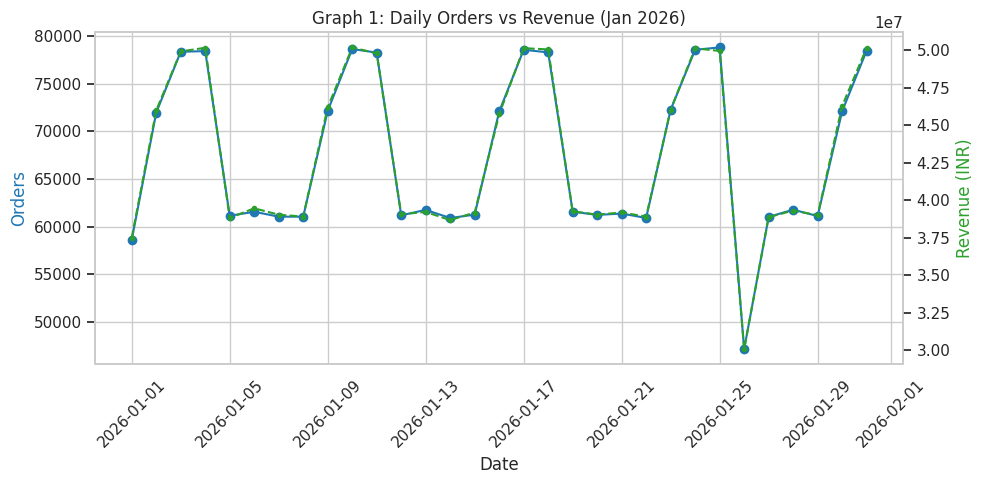

In [ ]:
fig, ax1 = plt.subplots()
ax1.plot(p1["order_date"], p1["orders"], color="tab:blue", marker="o")
ax1.set_xlabel("Date")
ax1.set_ylabel("Orders", color="tab:blue")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(p1["order_date"], p1["revenue"], color="tab:green", linestyle="--", marker=".")
ax2.set_ylabel("Revenue (INR)", color="tab:green")
ax2.grid(False)

plt.title("Graph 1: Daily Orders vs Revenue (Jan 2026)")
plt.tight_layout()
plt.show()

### Query 2: Payment mode, revenue and tips

CASE WHEN turns the numeric payment code into a readable name. Cash on delivery shows an average tip of 0 only because tips paid in cash are never recorded in the system, so any tip analysis has to use digital payments only. This is why Queries 7 and 8 filter out code 3.

In [ ]:
q2 = """
SELECT
  CASE payment_code
    WHEN 1 THEN 'UPI'
    WHEN 2 THEN 'Card'
    WHEN 3 THEN 'Cash on Delivery'
    WHEN 4 THEN 'Wallet'
    WHEN 5 THEN 'Net Banking'
    ELSE 'Unknown'
  END AS pay_mode,
  COUNT(*) AS orders,
  ROUND(SUM(total_amount), 2) AS revenue,
  ROUND(AVG(tip), 2) AS avg_tip
FROM food_db
GROUP BY payment_code
ORDER BY revenue DESC
"""
spark.sql(q2).show()

+----------------+-------+--------------+-------+
|        pay_mode| orders|       revenue|avg_tip|
+----------------+-------+--------------+-------+
|             UPI|1150422|7.3668789578E8|  19.52|
|            Card| 705786|4.5116386563E8|  19.52|
|Cash on Delivery| 211979| 1.310142339E8|    0.0|
|          Wallet|  23084| 1.476756986E7|  19.66|
|     Net Banking|    481|     317983.95|  21.43|
|         Unknown|      2|       1786.68|    0.0|
+----------------+-------+--------------+-------+



### Query 3: Items per order

Groups by the number of items to see basket size. The NULL group is orders where the item count was not recorded. It is kept on purpose, because a group by shows missing values as their own group and that is a quick data quality check.

In [ ]:
q3 = """
SELECT
  items_count,
  COUNT(*) AS orders,
  ROUND(SUM(total_amount), 2) AS revenue,
  ROUND(AVG(order_value), 2) AS avg_value,
  ROUND(AVG(distance_km), 2) AS avg_km
FROM food_db
GROUP BY items_count
ORDER BY items_count
"""
spark.sql(q3).show()

+-----------+------+--------------+---------+------+
|items_count|orders|       revenue|avg_value|avg_km|
+-----------+------+--------------+---------+------+
|       NULL| 41714| 2.666307075E7|   616.87|  4.58|
|          1|646474|1.3884497586E8|   181.78|  4.59|
|          2|302640|1.1628418753E8|   361.71|  4.59|
|          3|239501|1.3344016259E8|   541.75|  4.59|
|          4|205918|1.5122091921E8|   721.92|  4.59|
|          5|184242|1.6868143126E8|    902.4|  4.59|
|          6|168813|1.8514522713E8|   1081.9|  4.59|
|          7|156133|1.9972810344E8|  1261.78|   4.6|
|          8|146319|2.1394525803E8|  1441.55|  4.59|
+-----------+------+--------------+---------+------+



### Query 4: Delivery distance tiers

Uses CASE to bin distance into five tiers, then counts orders and the average bill per tier. GROUP BY 1 groups by the first selected column, which is the CASE expression, so it does not have to be written twice.

In [ ]:
q4 = """
SELECT
  CASE
    WHEN distance_km <= 2 THEN '0-2 km'
    WHEN distance_km <= 5 THEN '2-5 km'
    WHEN distance_km <= 8 THEN '5-8 km'
    WHEN distance_km <= 12 THEN '8-12 km'
    ELSE '12+ km'
  END AS dist_tier,
  COUNT(*) AS orders,
  ROUND(AVG(total_amount), 2) AS avg_bill,
  ROUND(AVG(delivery_fee), 2) AS avg_del_fee
FROM food_db
GROUP BY 1
ORDER BY orders DESC
"""
spark.sql(q4).show()

+---------+------+--------+-----------+
|dist_tier|orders|avg_bill|avg_del_fee|
+---------+------+--------+-----------+
|   2-5 km|990230|  633.22|      25.56|
|   5-8 km|538374|  644.28|       37.2|
|   0-2 km|324072|  624.98|      17.71|
|  8-12 km|208788|  656.16|      49.94|
|   12+ km| 30290|  677.61|      65.92|
+---------+------+--------+-----------+



### Query 5: Top 10 restaurant zones

Ranks restaurant zones by order count with GROUP BY, ORDER BY and LIMIT. It is the SQL version of the RDD reduceByKey done in Phase 1, so the counts of the top zones should match the takeOrdered output there.

In [ ]:
q5 = """
SELECT
  rest_zone,
  COUNT(*) AS orders,
  ROUND(SUM(total_amount), 2) AS revenue,
  ROUND(AVG(distance_km), 2) AS avg_km,
  ROUND(AVG(order_value), 2) AS avg_value
FROM food_db
GROUP BY rest_zone
ORDER BY orders DESC
LIMIT 10
"""
spark.sql(q5).show()

+---------+------+--------------+------+---------+
|rest_zone|orders|       revenue|avg_km|avg_value|
+---------+------+--------------+------+---------+
|        1|330225|2.0953762343E8|  3.39|   617.33|
|        2|136911|  8.67064929E7|  3.79|   614.45|
|        3|105026| 6.700770387E7|  4.15|   617.59|
|        4| 89174| 5.685330839E7|  4.43|   616.49|
|        5| 77806| 4.968745989E7|  4.65|   616.55|
|        6| 70700| 4.515485132E7|  4.81|   615.61|
|        7| 64995| 4.124421915E7|  4.92|   611.83|
|        8| 59670| 3.804242545E7|  5.03|   613.75|
|        9| 56485| 3.618790749E7|  5.08|   616.42|
|       10| 54014| 3.470279654E7|  5.11|   618.67|
+---------+------+--------------+------+---------+



## Phase 3: Diagnostic analytics (Queries 6 to 10)

### Query 6: Rush hour slowdown vs earning rate (Graph 2)

Splits the day into five time windows with HOUR(). Delivery duration comes from subtracting UNIX_TIMESTAMP of order time from that of delivery time. Two metrics are compared:

- effective speed in km per hour (distance divided by total time, which includes kitchen preparation)
- revenue per minute (total amount divided by delivery minutes)

Durations under 2 minutes or over 180 minutes are treated as bad data. A CTE (WITH clause) computes the columns first and the outer query aggregates them. Graph 2 shows speed as bars and earning rate as a line.

In [ ]:
q6 = """
WITH d AS (
  SELECT
    CASE
      WHEN HOUR(order_ts) BETWEEN 6 AND 10 THEN '1. Breakfast'
      WHEN HOUR(order_ts) BETWEEN 11 AND 15 THEN '2. Lunch'
      WHEN HOUR(order_ts) BETWEEN 16 AND 18 THEN '3. Evening Snack'
      WHEN HOUR(order_ts) BETWEEN 19 AND 22 THEN '4. Dinner Rush'
      ELSE '5. Late Night'
    END AS time_bucket,
    distance_km,
    (UNIX_TIMESTAMP(delivered_ts) - UNIX_TIMESTAMP(order_ts)) / 60.0 AS dur_min,
    total_amount
  FROM food_db
  WHERE delivered_ts > order_ts
)
SELECT
  time_bucket,
  COUNT(*) AS orders,
  ROUND(AVG(distance_km / (dur_min / 60.0)), 2) AS avg_speed_kmph,
  ROUND(AVG(total_amount / dur_min), 2) AS rev_per_min
FROM d
WHERE dur_min BETWEEN 2 AND 180
GROUP BY time_bucket
ORDER BY time_bucket
"""
p6 = spark.sql(q6).toPandas()
print("Query 6: speed vs revenue rate")
print(p6)

Query 6: speed vs revenue rate
        time_bucket  orders  avg_speed_kmph  rev_per_min
0      1. Breakfast  281066           11.58        33.03
1          2. Lunch  687623           10.46        30.42
2  3. Evening Snack  304537           11.93        33.64
3    4. Dinner Rush  708676            9.68        28.44
4     5. Late Night  109852           16.96        45.18


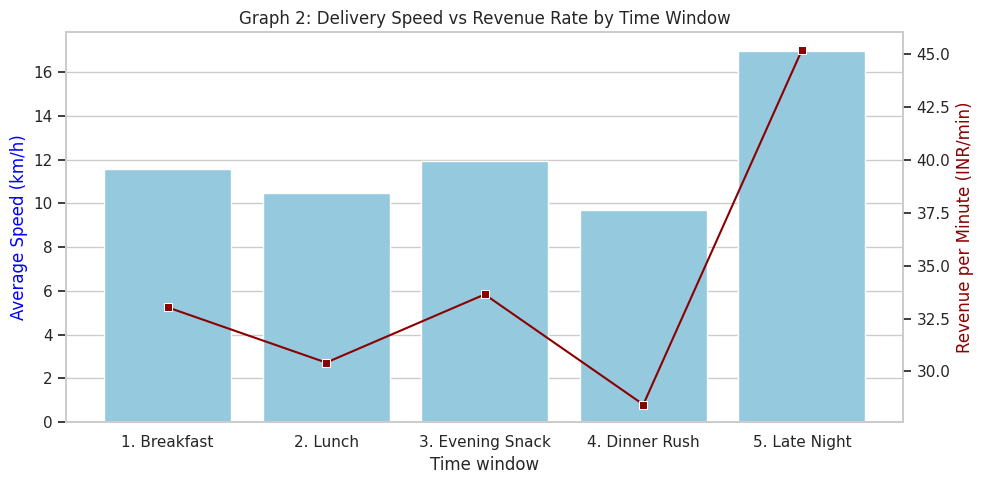

In [ ]:
fig, ax1 = plt.subplots()
sns.barplot(data=p6, x="time_bucket", y="avg_speed_kmph", color="skyblue", ax=ax1)
ax1.set_ylabel("Average Speed (km/h)", color="blue")
ax1.set_xlabel("Time window")

ax2 = ax1.twinx()
sns.lineplot(data=p6, x="time_bucket", y="rev_per_min", color="darkred", marker="s", ax=ax2)
ax2.set_ylabel("Revenue per Minute (INR/min)", color="darkred")
ax2.grid(False)

plt.title("Graph 2: Delivery Speed vs Revenue Rate by Time Window")
plt.tight_layout()
plt.show()

### Query 7: Hour over hour tip rate (LAG window function)

First a CTE finds the average tip percentage for each hour, using digital payments only. Then LAG(avg_tip_pct, 1) OVER (ORDER BY pickup hour) brings the previous hour's value onto the same row, and the difference gives the hour over hour change. A large negative delta marks the hour where tipping drops. Unlike GROUP BY, the window function keeps all 24 rows. There is no PARTITION BY, so Spark moves all rows of the window to one partition, which is fine here because the CTE has only 24 rows.

In [ ]:
q7 = """
WITH hourly AS (
  SELECT
    HOUR(order_ts) AS order_hour,
    ROUND(AVG(tip / order_value * 100), 2) AS avg_tip_pct
  FROM food_db
  WHERE payment_code IN (1, 2, 4, 5)
  GROUP BY HOUR(order_ts)
)
SELECT
  order_hour,
  avg_tip_pct,
  LAG(avg_tip_pct, 1) OVER (ORDER BY order_hour) AS prev_hour_pct,
  ROUND(avg_tip_pct - LAG(avg_tip_pct, 1) OVER (ORDER BY order_hour), 2) AS hourly_delta
FROM hourly
ORDER BY order_hour
"""
spark.sql(q7).show(24)

+----------+-----------+-------------+------------+
|order_hour|avg_tip_pct|prev_hour_pct|hourly_delta|
+----------+-----------+-------------+------------+
|         0|       5.01|         NULL|        NULL|
|         1|        5.0|         5.01|       -0.01|
|         2|       5.13|          5.0|        0.13|
|         3|       5.14|         5.13|        0.01|
|         4|       4.92|         5.14|       -0.22|
|         5|       5.04|         4.92|        0.12|
|         6|       4.19|         5.04|       -0.85|
|         7|       4.15|         4.19|       -0.04|
|         8|       4.19|         4.15|        0.04|
|         9|       4.13|         4.19|       -0.06|
|        10|       4.17|         4.13|        0.04|
|        11|       4.16|         4.17|       -0.01|
|        12|        3.6|         4.16|       -0.56|
|        13|       3.59|          3.6|       -0.01|
|        14|       3.61|         3.59|        0.02|
|        15|        4.2|         3.61|        0.59|
|        16|

### Query 8: Do surge fees reduce tips?

Cross classifies digital payment orders by surge fee (charged or not) and distance category (short, medium, long), then compares the average tip percentage in each cell. Comparing inside the same distance category matters. Otherwise the result could just reflect that short orders and long orders tip differently. Because tipping in this dataset was built to drop when a surge fee is charged, the query should show that gap.

In [ ]:
q8 = """
SELECT
  CASE WHEN surge_fee > 0 THEN 'Surge Charged' ELSE 'No Surge' END AS surge_status,
  CASE
    WHEN distance_km <= 3 THEN 'Short (<3 km)'
    WHEN distance_km <= 8 THEN 'Medium (3-8 km)'
    ELSE 'Long (>8 km)'
  END AS dist_cat,
  COUNT(*) AS orders,
  ROUND(AVG(tip / order_value * 100), 2) AS avg_tip_pct
FROM food_db
WHERE payment_code IN (1, 2, 4, 5)
GROUP BY 1, 2
ORDER BY dist_cat, surge_status
"""
spark.sql(q8).show()

+-------------+---------------+------+-----------+
| surge_status|       dist_cat|orders|avg_tip_pct|
+-------------+---------------+------+-----------+
|     No Surge|   Long (>8 km)|146345|       4.26|
|Surge Charged|   Long (>8 km)| 68578|       3.21|
|     No Surge|Medium (3-8 km)|705073|       4.27|
|Surge Charged|Medium (3-8 km)|333528|       3.21|
|     No Surge|  Short (<3 km)|425589|       4.28|
|Surge Charged|  Short (<3 km)|200660|       3.21|
+-------------+---------------+------+-----------+



### Query 9: High value delivery corridors

A corridor is a pair of restaurant zone and customer zone. Revenue per km is total revenue divided by total distance (a ratio of sums, which is more stable than averaging per order ratios). HAVING COUNT(*) > 1000 keeps only busy corridors, because HAVING filters after grouping while WHERE filters before it. Very short, same zone deliveries tend to top this list because the fixed part of the bill is spread over very few kilometres.

In [ ]:
q9 = """
SELECT
  rest_zone,
  cust_zone,
  COUNT(*) AS volume,
  ROUND(AVG(distance_km), 2) AS avg_km,
  ROUND(AVG(total_amount), 2) AS avg_bill,
  ROUND(SUM(total_amount) / SUM(distance_km), 2) AS rev_per_km
FROM food_db
GROUP BY rest_zone, cust_zone
HAVING COUNT(*) > 1000
ORDER BY rev_per_km DESC
LIMIT 10
"""
spark.sql(q9).show()

+---------+---------+------+------+--------+----------+
|rest_zone|cust_zone|volume|avg_km|avg_bill|rev_per_km|
+---------+---------+------+------+--------+----------+
|       35|       35|  2282|  1.58|  629.11|    397.51|
|       22|       22|  2859|  1.59|  632.97|    396.93|
|       26|       26|  2605|  1.59|  629.71|    395.66|
|       16|       16|  3330|  1.59|  627.04|     395.6|
|        4|        4|  7092|   1.6|  631.07|    395.28|
|       12|       12|  3776|   1.6|  629.94|    394.75|
|       21|       21|  2888|  1.61|  634.01|    394.27|
|        3|        3|  8526|   1.6|  629.12|    394.01|
|       34|       34|  2280|   1.6|  627.65|    393.43|
|       15|       15|  3425|   1.6|  630.83|    393.28|
+---------+---------+------+------+--------+----------+



### Query 10: Revenue per minute outliers across fare deciles (NTILE and CTEs) (Graph 3)

Two CTEs are chained. The first computes delivery duration. The second computes revenue per minute and uses NTILE(10) OVER (ORDER BY total_amount) to cut all orders into 10 equal sized fare buckets (decile 1 is the cheapest 10 percent of orders, decile 10 the most expensive). The final query compares the average against the maximum revenue per minute in each decile. A huge gap between the two means a few records are behaving abnormally, such as a pricing or metering error. Graph 3 uses a log scale on the y axis so that the tiny average and the huge maximum can be seen together.

NTILE with a global ORDER BY sorts all rows in one partition, so on a much bigger dataset this query would need a partition column or an approximate percentile instead.

In [ ]:
q10 = """
WITH valid AS (
  SELECT
    total_amount,
    (UNIX_TIMESTAMP(delivered_ts) - UNIX_TIMESTAMP(order_ts)) / 60.0 AS dur_min
  FROM food_db
  WHERE total_amount > 0 AND delivered_ts > order_ts
),
ranked AS (
  SELECT
    total_amount,
    dur_min,
    total_amount / NULLIF(dur_min, 0) AS rev_per_min,
    NTILE(10) OVER (ORDER BY total_amount) AS fare_decile
  FROM valid
  WHERE dur_min >= 2 AND dur_min <= 180
)
SELECT
  fare_decile,
  ROUND(AVG(rev_per_min), 2) AS avg_rev_per_min,
  ROUND(MAX(rev_per_min), 2) AS max_rev_per_min
FROM ranked
GROUP BY fare_decile
ORDER BY fare_decile
"""
p10 = spark.sql(q10).toPandas()
print("Query 10: fare decile anomalies")
print(p10)

Query 10: fare decile anomalies
   fare_decile  avg_rev_per_min  max_rev_per_min
0            1             8.44            31.04
1            2            10.00            36.90
2            3            12.00            47.35
3            4            14.74            60.43
4            5            21.34            80.62
5            6            27.54           109.02
6            7            35.71           128.89
7            8            44.90           171.87
8            9            56.12           215.43
9           10            82.62          5007.80


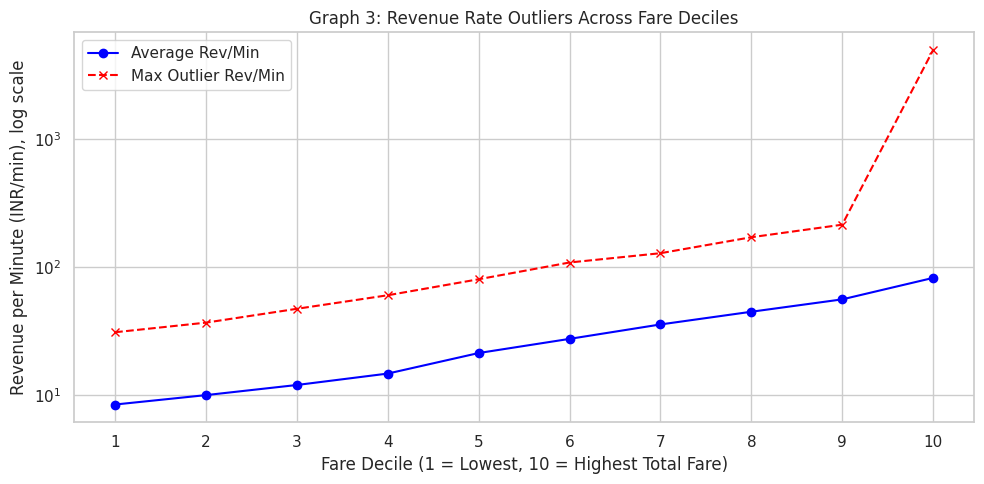

In [ ]:
fig, ax = plt.subplots()
ax.plot(p10["fare_decile"], p10["avg_rev_per_min"], color="blue", marker="o", label="Average Rev/Min")
ax.plot(p10["fare_decile"], p10["max_rev_per_min"], color="red", linestyle="--", marker="x", label="Max Outlier Rev/Min")
ax.set_yscale("log")
ax.set_xticks(range(1, 11))
ax.set_xlabel("Fare Decile (1 = Lowest, 10 = Highest Total Fare)")
ax.set_ylabel("Revenue per Minute (INR/min), log scale")
ax.set_title("Graph 3: Revenue Rate Outliers Across Fare Deciles")
ax.legend()
plt.tight_layout()
plt.show()

## Observations

Read these against your own output. The data is synthetic, so these patterns come from how it was built and not from the real market.

- Query 1 and Graph 1: orders and revenue rise and fall together. Weekends are higher, and 1 Jan and 26 Jan are visible dips.
- Query 2: UPI and Card carry most of the revenue. Cash on Delivery shows an average tip of 0 because cash tips are not recorded, so tip analysis must use digital payments.
- Query 3: single item orders are the most common. Order value grows with the item count, but average distance stays flat, so basket size and distance are independent here.
- Query 4: most deliveries fall in the 2 to 8 km tiers, and the average delivery fee rises with distance.
- Query 5: order volume is very skewed. Zone 1 alone has roughly 15 percent of all orders.
- Query 6 and Graph 2: effective speed is lowest in the dinner rush and lunch windows and highest late at night. Revenue per minute follows the same shape, because slow deliveries earn less per minute.
- Query 7: the tip percentage falls at the start of the lunch (12) and dinner (19) windows and recovers at 15 and 22. These are the hours where surge fees start and stop.
- Query 8: in every distance category, orders with a surge fee have a lower average tip percentage (about 3.2 against about 4.3 in this run), so the surge fee takes away part of the tip.
- Query 9: the highest revenue per km corridors are same zone deliveries. They are very short, so the fixed part of the bill is spread over few kilometres.
- Query 10 and Graph 3: the average revenue per minute rises smoothly with the fare decile, but the maximum in decile 10 jumps to thousands of INR per minute. These are the glitch orders (large value delivered in 3 minutes) and are the records to audit.

## Conclusion

This experiment built an end to end distributed analytics pipeline in PySpark on about 2 million food delivery orders. Low level RDD operations (filter, map, reduceByKey) handled cleaning and per zone aggregation, and the cleaned data was registered as a Spark SQL view for ten analytical queries. Spark's in memory execution and the Catalyst optimizer made grouping, CASE binning, HAVING filters, and the LAG and NTILE window functions run quickly. Only small aggregated results were converted to Pandas for plotting, which keeps the driver memory safe and gives a pattern that scales to much larger data.